# 02 – Exploratory Data Analysis (EDA) and Statistical Analysis
We study the cleaned data to understand **what drives traffic volume and congestion**.
* Univariate – one variable at a time
* Bivariate – target vs one feature
* Multivariate – several features together
* Statistical tests – are the differences we see real or just chance?

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats            # statistical tests

import data_preprocessing as dp

sns.set_theme(style="whitegrid")
IMG = "../Images/"
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

df = dp.load_clean_featured()      # cleaned data + engineered features + congestion label
print(df.shape)
df.head()

(40564, 18)


,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,is_holiday,temp_c,hour,day_of_week,month,year,is_weekend,is_rush_hour,hour_sin,hour_cos,congestion_level
0,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,0,15.13,9,1,10,2012,0,1,7.071068e-01,-0.707107,High
1,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,0,16.21,10,1,10,2012,0,0,5.000000e-01,-0.866025,High
2,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,0,16.43,11,1,10,2012,0,0,2.588190e-01,-0.965926,High
3,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,0,16.98,12,1,10,2012,0,0,1.224647e-16,-1.000000,High
4,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,0,17.99,13,1,10,2012,0,0,-2.588190e-01,-0.965926,High


## 1. Univariate analysis

In [2]:
df[["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
traffic_volume,40564.0,3291.08,1984.64,0.00,1249.75,3429.00,4952.00,7280.00
temp_c,40564.0,8.24,13.09,-29.76,-1.30,9.72,19.13,36.92
rain_1h,40564.0,0.08,0.77,0.00,0.00,0.00,0.00,55.63
snow_1h,40564.0,0.00,0.01,0.00,0.00,0.00,0.00,0.51
clouds_all,40564.0,44.21,38.68,0.00,1.00,40.00,90.00,100.00


In [3]:
print("Skewness of traffic_volume:", round(df["traffic_volume"].skew(), 3))
print("Hours with any rain:", (df["rain_1h"] > 0).mean().round(3) * 100, "%")
print("Hours with any snow:", (df["snow_1h"] > 0).mean().round(4) * 100, "%")

Skewness of traffic_volume: -0.108
Hours with any rain: 5.1 %
Hours with any snow: 0.08 %


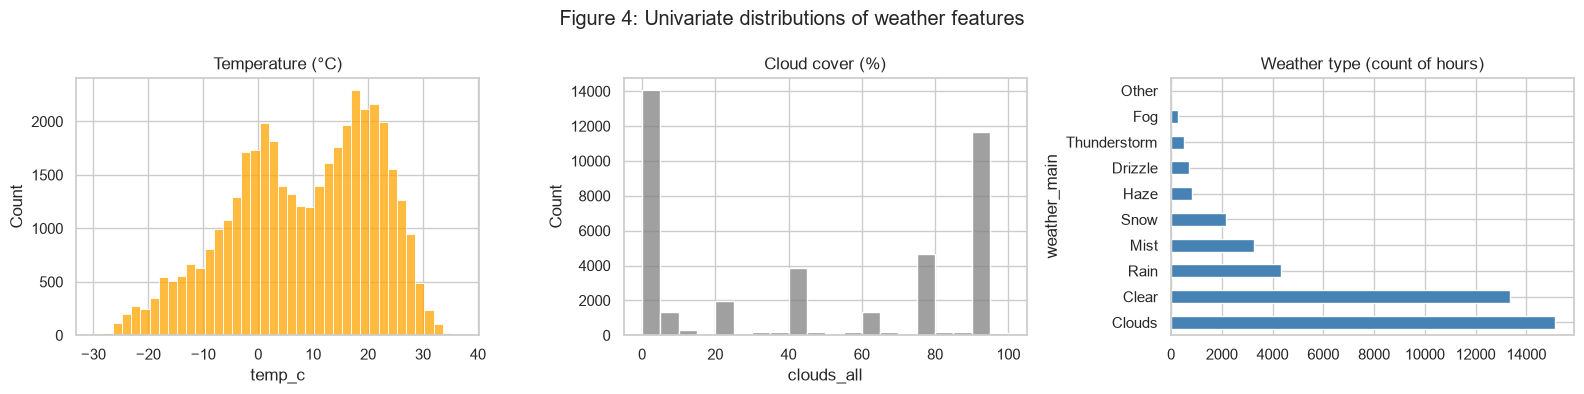

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["temp_c"], bins=40, ax=axes[0], color="orange").set_title("Temperature (°C)")
sns.histplot(df["clouds_all"], bins=20, ax=axes[1], color="grey").set_title("Cloud cover (%)")
df["weather_main"].value_counts().plot(kind="barh", ax=axes[2], color="steelblue")
axes[2].set_title("Weather type (count of hours)")
plt.suptitle("Figure 4: Univariate distributions of weather features")
plt.tight_layout()
plt.savefig(IMG + "02_univariate_weather.png", dpi=120)
plt.show()

**Interpretation:**
* Traffic volume is almost symmetric (skew ≈ 0) but **bimodal** (night vs day).
* Temperature ranges from about −30 °C to +36 °C – Minnesota has very cold winters.
* `rain_1h` and `snow_1h` are **zero most of the time** → they are very skewed and will carry little
  information. Weather is better described by the categorical `weather_main`.
* Clouds and Clear are the most common weather types.

## 2. Bivariate analysis – traffic volume vs time features

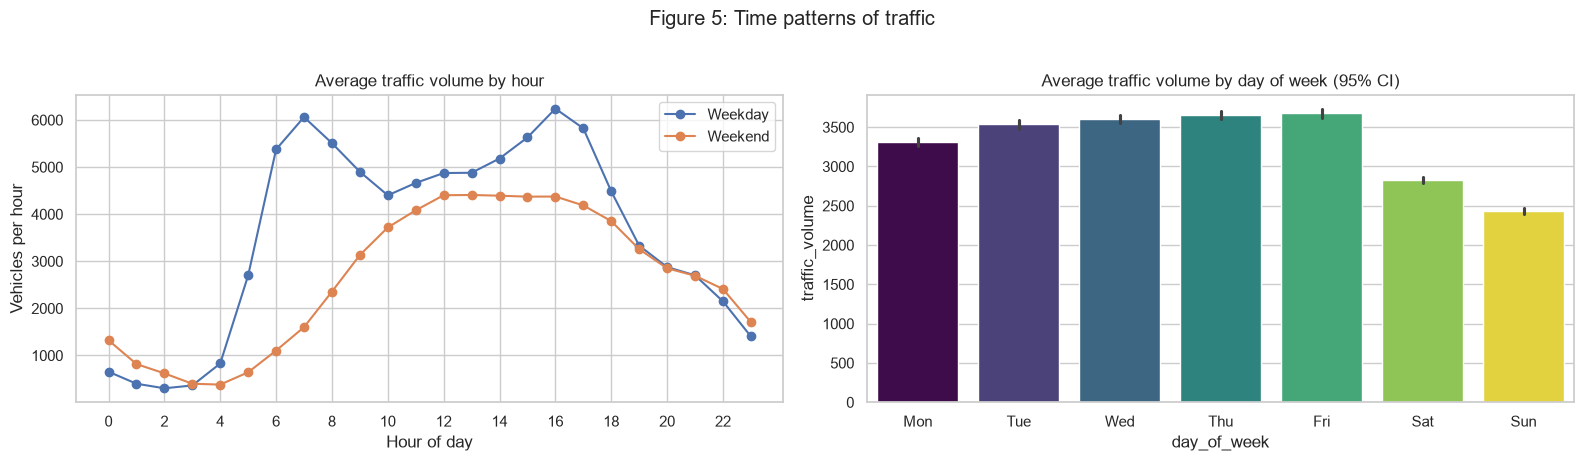

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
hourly = df.groupby(["hour", "is_weekend"])["traffic_volume"].mean().unstack()
hourly.columns = ["Weekday", "Weekend"]
hourly.plot(ax=axes[0], marker="o")
axes[0].set_title("Average traffic volume by hour")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Vehicles per hour")
axes[0].set_xticks(range(0, 24, 2))

sns.barplot(data=df, x="day_of_week", y="traffic_volume", ax=axes[1], palette="viridis", hue="day_of_week", legend=False,
            errorbar=("ci", 95))
axes[1].set_xticks(range(7), DAYS)
axes[1].set_title("Average traffic volume by day of week (95% CI)")
plt.suptitle("Figure 5: Time patterns of traffic", y=1.02)
plt.tight_layout()
plt.savefig(IMG + "02_hour_day_patterns.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretation:**
* On **weekdays** there are two clear peaks – **morning rush (6–8 AM)** and **evening rush (3–5 PM)**.
* On **weekends** there is no morning peak; traffic rises slowly to a single midday hump.
* Weekdays (Mon–Fri) carry much more traffic than Saturday and especially Sunday.
* So **hour** and **day of week** (and their interaction) are the key predictors.

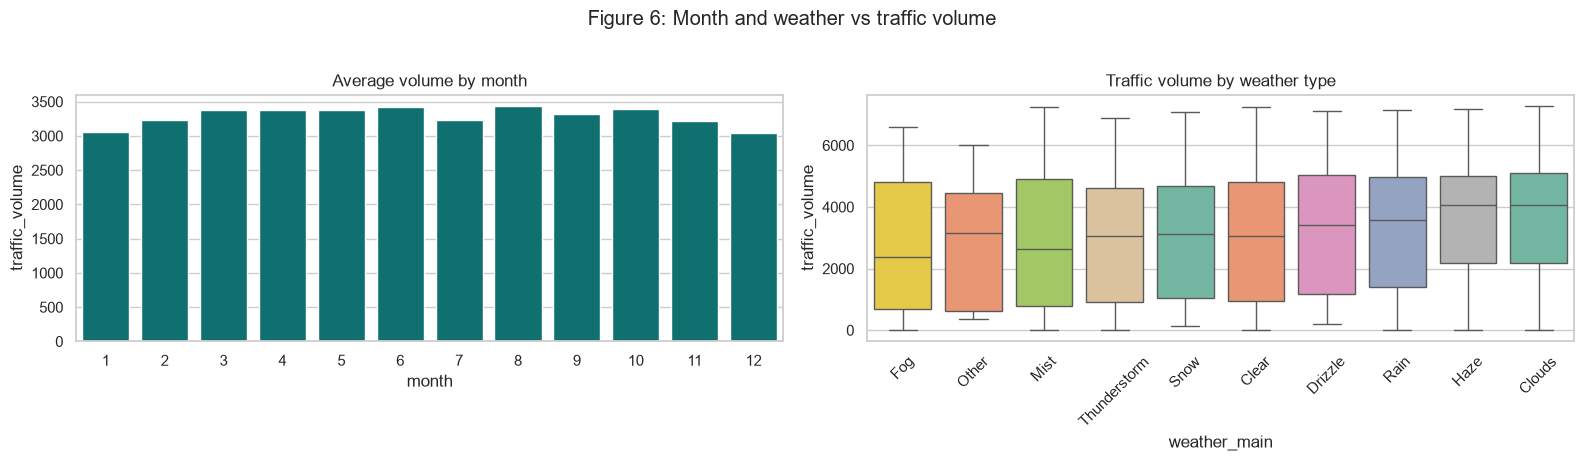

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.barplot(data=df, x="month", y="traffic_volume", ax=axes[0], color="teal", errorbar=None)
axes[0].set_title("Average volume by month")
order = df.groupby("weather_main")["traffic_volume"].mean().sort_values().index
sns.boxplot(data=df, x="weather_main", y="traffic_volume", order=order, ax=axes[1], palette="Set2", hue="weather_main", legend=False)
axes[1].set_title("Traffic volume by weather type")
axes[1].tick_params(axis="x", rotation=45)
plt.suptitle("Figure 6: Month and weather vs traffic volume", y=1.02)
plt.tight_layout()
plt.savefig(IMG + "02_month_weather.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
# Group-wise comparison table
grp = df.groupby("weather_main")["traffic_volume"].agg(["count", "mean", "median", "std"]).round(0)
grp.sort_values("mean")

,count,mean,median,std
weather_main,,,,
Fog,293,2728.0,2379.0,2143.0
Other,13,2781.0,3139.0,2186.0
Mist,3277,2857.0,2624.0,2147.0
Thunderstorm,499,3023.0,3045.0,1972.0
Snow,2161,3039.0,3107.0,1911.0
Clear,13355,3057.0,3045.0,1987.0
Drizzle,689,3251.0,3404.0,2017.0
Rain,4341,3355.0,3587.0,1974.0
Haze,812,3571.0,4048.0,1829.0


**Interpretation:** month-to-month differences are small (slightly lower in December/January).
Weather types show different medians, **but** part of this is a time effect – e.g. *Fog* and *Mist*
happen mostly early in the morning when traffic is low anyway. Weather effect is weaker than the
time-of-day effect.

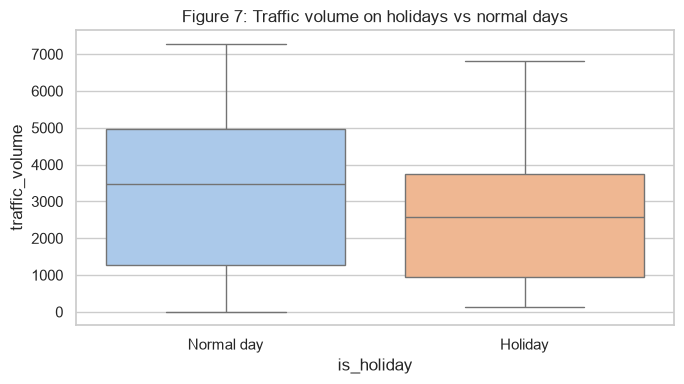

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="is_holiday", y="traffic_volume", palette="pastel", hue="is_holiday", legend=False, ax=ax)
ax.set_xticks([0, 1], ["Normal day", "Holiday"])
ax.set_title("Figure 7: Traffic volume on holidays vs normal days")
plt.tight_layout()
plt.savefig(IMG + "02_holiday.png", dpi=120)
plt.show()

## 3. Multivariate analysis

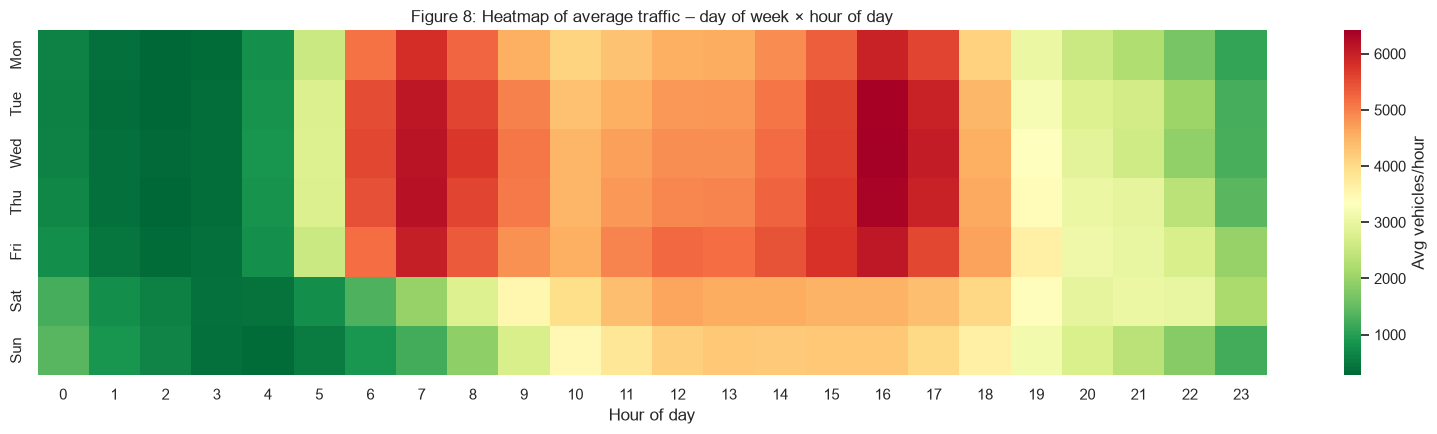

In [9]:
pivot = df.pivot_table(index="day_of_week", columns="hour", values="traffic_volume", aggfunc="mean")
pivot.index = DAYS
plt.figure(figsize=(16, 4.5))
sns.heatmap(pivot, cmap="RdYlGn_r", cbar_kws={"label": "Avg vehicles/hour"})
plt.title("Figure 8: Heatmap of average traffic – day of week × hour of day")
plt.xlabel("Hour of day"); plt.ylabel("")
plt.tight_layout()
plt.savefig(IMG + "02_heatmap_day_hour.png", dpi=120)
plt.show()

**Interpretation (most important insight):** red blocks = congestion. Weekday **6–8 AM and 2–6 PM**
are the most congested time slots; nights (0–4 AM) are always green. This heatmap is basically the
"rule" our ML models need to learn.

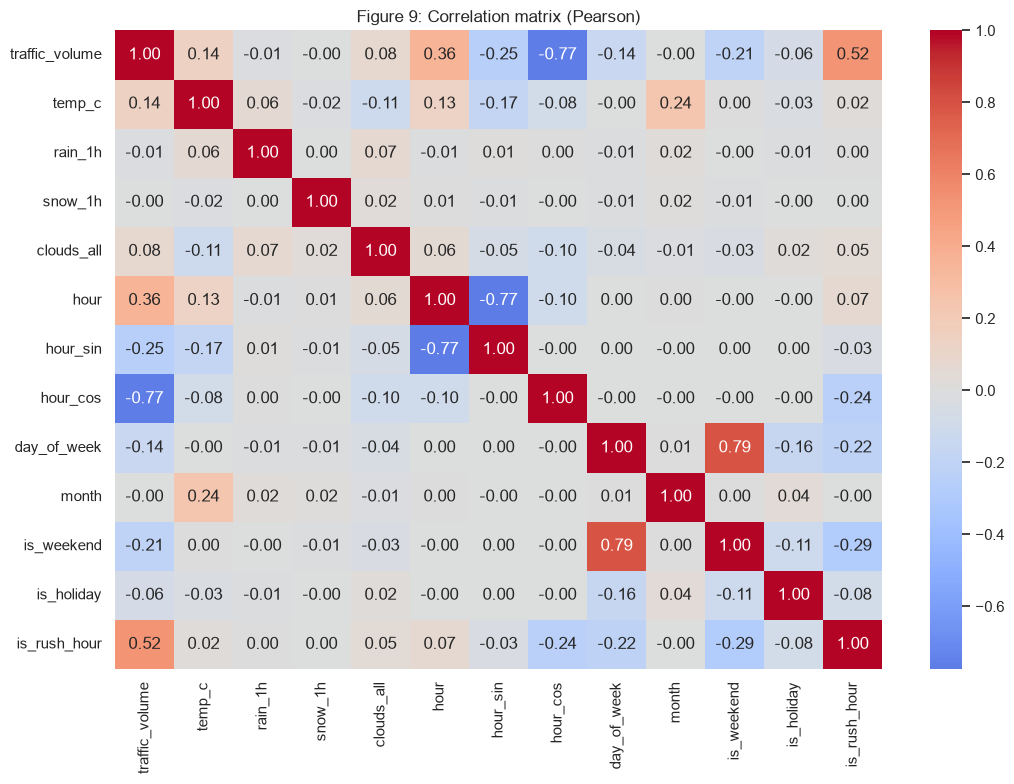

In [10]:
num_cols = ["traffic_volume", "temp_c", "rain_1h", "snow_1h", "clouds_all", "hour", "hour_sin",
            "hour_cos", "day_of_week", "month", "is_weekend", "is_holiday", "is_rush_hour"]
corr = df[num_cols].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Figure 9: Correlation matrix (Pearson)")
plt.tight_layout()
plt.savefig(IMG + "02_correlation.png", dpi=120)
plt.show()

In [11]:
corr["traffic_volume"].drop("traffic_volume").sort_values(key=abs, ascending=False).round(3)

hour_cos       -0.767
is_rush_hour    0.523
hour            0.355
hour_sin       -0.254
is_weekend     -0.212
day_of_week    -0.144
temp_c          0.139
clouds_all      0.078
is_holiday     -0.065
rain_1h        -0.013
month          -0.005
snow_1h        -0.002
Name: traffic_volume, dtype: float64

**Interpretation:**
* `hour_cos` has the strongest (negative) linear correlation – it is low at midday and high at
  midnight, matching the day/night cycle. Raw `hour` has a weaker linear correlation because the
  relation is **not linear** (it goes up and then down).
* `is_rush_hour` and `is_weekend` are strongly related to volume, as the plots showed.
* Weather numbers (`rain_1h`, `snow_1h`, `clouds_all`) have **near-zero correlation**.
* Low correlation does not always mean "useless" – tree models can still use non-linear patterns.
* Features are not highly correlated with each other (except hour/hour_sin/hour_cos, which is
  expected), so **multicollinearity** is not a big problem.

In [12]:
# Congestion class vs weekend / hour (association between categorical variables)
ct = pd.crosstab(df["is_weekend"].map({0: "Weekday", 1: "Weekend"}), df["congestion_level"],
                 normalize="index")[dp.CLASS_ORDER] * 100
ct.round(1)

congestion_level,Low,Medium,High
is_weekend,,,
Weekday,27.6,27.2,45.2
Weekend,39.1,48.6,12.3


## 4. Statistical tests
We use a significance level **α = 0.05**. If p-value < 0.05 → the difference is statistically significant.

### Test 1 – Welch's t-test: is weekday daytime traffic different from weekend daytime traffic?
* H₀: mean volume (7 AM–7 PM) on weekdays = weekends
* H₁: the means are different

In [13]:
day = df[df["hour"].between(7, 19)]
wk = day.loc[day["is_weekend"] == 0, "traffic_volume"]
we = day.loc[day["is_weekend"] == 1, "traffic_volume"]
t, p = stats.ttest_ind(wk, we, equal_var=False)
print(f"Weekday mean = {wk.mean():.0f}, Weekend mean = {we.mean():.0f}")
print(f"t = {t:.2f}, p-value = {p:.3e}")

# 95% confidence intervals for each mean
for name, s in [("Weekday", wk), ("Weekend", we)]:
    ci = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
    print(f"{name} 95% CI for mean volume: ({ci[0]:.0f}, {ci[1]:.0f})")

Weekday mean = 5074, Weekend mean = 3703
t = 88.50, p-value = 0.000e+00
Weekday 95% CI for mean volume: (5058, 5089)
Weekend 95% CI for mean volume: (3677, 3729)


**Result:** weekday daytime mean ≈ **5074** vehicles/h vs weekend ≈ **3703** (about 37% higher), t ≈ 88.5,
p-value ≈ 0 (< 0.05) → **reject H₀**. The 95% confidence intervals (5058–5089 vs 3677–3729) do not overlap,
so the difference is real, not chance.

### Test 2 – One-way ANOVA: does traffic volume differ across weather types (daytime hours only)?
We use only 7 AM–7 PM to reduce the time-of-day effect.

In [14]:
groups = [g["traffic_volume"].values for _, g in day.groupby("weather_main") if len(g) > 30]
f, p = stats.f_oneway(*groups)
print(f"F = {f:.2f}, p-value = {p:.3e}")
day.groupby("weather_main")["traffic_volume"].mean().sort_values().round(0)

F = 18.99, p-value = 1.009e-28


weather_main
Fog             4287.0
Snow            4354.0
Thunderstorm    4513.0
Haze            4523.0
Other           4606.0
Mist            4632.0
Clear           4663.0
Drizzle         4701.0
Rain            4728.0
Clouds          4746.0
Name: traffic_volume, dtype: float64

**Result:** F ≈ 19.0, p ≈ 1e-28 (< 0.05) → **reject H₀**: daytime traffic differs across weather types.
But the means only range from ≈ 4287 (Fog) to ≈ 4746 (Clouds) – about a **10% difference**, compared with
the **37%** weekday/weekend difference. Weather is statistically significant but a **weaker** factor
(with ~40,000 rows even small differences become "significant", so we must also look at effect size).

### Test 3 – Chi-square test of independence: congestion level vs weekend

In [15]:
table = pd.crosstab(df["is_weekend"], df["congestion_level"])
chi2, p, dof, _ = stats.chi2_contingency(table)
print(table, "\n")
print(f"Chi-square = {chi2:.1f}, dof = {dof}, p-value = {p:.3e}")
# Cramér's V – strength of association (0 = none, 1 = perfect)
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
print(f"Cramér's V = {cramers_v:.3f}")

congestion_level   High   Low  Medium
is_weekend                           
0                 13090  8000    7884
1                  1423  4536    5631 

Chi-square = 3995.7, dof = 2, p-value = 0.000e+00
Cramér's V = 0.314


**Result:** χ² ≈ 3996, p ≈ 0 → congestion level **depends on** weekday/weekend. Cramér's V ≈ **0.31** =
moderate association. On weekdays **45%** of hours are High congestion, on weekends only **12%**.

## 5. EDA summary – key findings
1. **Hour of day** is the strongest driver (two weekday rush-hour peaks, very low at night).
2. **Weekday vs weekend** and **holidays** change the daily pattern significantly (t-test, chi-square).
3. **Weather** has a statistically significant but much smaller effect than time.
4. The hour–volume relation is **non-linear** → simple linear models will struggle unless hour is
   one-hot encoded; tree-based models (Decision Tree, Random Forest) should perform best.
5. The data has a gap in 2014–2015, and the target classes are roughly balanced.